# K-Means Clustering

## Import Library

In [1]:
#202431163_Maftuh Faisal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
#202431163_Maftuh Faisal
data = pd.read_csv("fifa-22.csv", low_memory=False)
data.head()

,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,...,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,...,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,...,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png
3,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Júnior,"LW, CAM",91,91,129000000.0,270000.0,29,...,50+3,50+3,50+3,62+3,20+3,https://cdn.sofifa.net/players/190/871/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,NaN,https://cdn.sofifa.net/flags/br.png
4,192985,https://sofifa.com/player/192985/kevin-de-bruy...,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,125500000.0,350000.0,30,...,69+3,69+3,69+3,75+3,21+3,https://cdn.sofifa.net/players/192/985/22_120.png,https://cdn.sofifa.net/teams/10/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1325/60.png,https://cdn.sofifa.net/flags/be.png


In [3]:
#202431163_Maftuh Faisal
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Columns: 110 entries, sofifa_id to nation_flag_url
dtypes: float64(16), int64(44), str(50)
memory usage: 16.1 MB


In [4]:
#202431163_Maftuh Faisal
data.describe()

,sofifa_id,overall,potential,value_eur,wage_eur,age,height_cm,weight_kg,club_team_id,league_level,...,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed
count,19239.000000,19239.000000,19239.000000,1.916500e+04,19178.000000,19239.000000,19239.000000,19239.000000,19178.000000,19178.000000,...,19239.000000,19239.000000,19239.000000,19239.000000,19239.000000,19239.000000,19239.000000,19239.000000,19239.000000,2132.000000
mean,231468.086959,65.772182,71.079370,2.850452e+06,9017.989363,25.210822,181.299704,74.943032,50580.498123,1.354364,...,57.929830,46.601746,48.045584,45.906700,16.406102,16.192474,16.055356,16.229274,16.491814,36.439962
std,27039.717497,6.880232,6.086213,7.613700e+06,19470.176724,4.748235,6.863179,7.069434,54401.868535,0.747865,...,12.159326,20.200807,21.232718,20.755683,17.574028,16.839528,16.564554,17.059779,17.884833,10.751563
min,41.000000,47.000000,49.000000,9.000000e+03,500.000000,16.000000,155.000000,49.000000,1.000000,1.000000,...,12.000000,4.000000,5.000000,5.000000,2.000000,2.000000,2.000000,2.000000,2.000000,15.000000
25%,214413.500000,61.000000,67.000000,4.750000e+05,1000.000000,21.000000,176.000000,70.000000,479.000000,1.000000,...,50.000000,29.000000,28.000000,25.000000,8.000000,8.000000,8.000000,8.000000,8.000000,27.000000
50%,236543.000000,66.000000,71.000000,9.750000e+05,3000.000000,25.000000,181.000000,75.000000,1938.000000,1.000000,...,59.000000,52.000000,56.000000,53.000000,11.000000,11.000000,11.000000,11.000000,11.000000,36.000000
75%,253532.500000,70.000000,75.000000,2.000000e+06,8000.000000,29.000000,186.000000,80.000000,111139.000000,1.000000,...,66.000000,63.000000,65.000000,63.000000,14.000000,14.000000,14.000000,14.000000,14.000000,45.000000
max,264640.000000,93.000000,95.000000,1.940000e+08,350000.000000,54.000000,206.000000,110.000000,115820.000000,5.000000,...,96.000000,93.000000,93.000000,92.000000,91.000000,92.000000,93.000000,92.000000,90.000000,65.000000


In [5]:
#202431163_Maftuh Faisal
df = data.copy()
df = df[['shooting', 'defending']]
df.head()

,shooting,defending
0,92.0,34.0
1,92.0,44.0
2,94.0,34.0
3,83.0,37.0
4,86.0,64.0


In [6]:
#202431163_Maftuh Faisal
df.isnull().sum()

shooting     2132
defending    2132
dtype: int64

In [7]:
#202431163_Maftuh Faisal
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 17107 entries, 0 to 19238
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   shooting   17107 non-null  float64
 1   defending  17107 non-null  float64
dtypes: float64(2)
memory usage: 400.9 KB


In [8]:
#202431163_Maftuh Faisal
df.isnull().sum()

shooting     0
defending    0
dtype: int64

In [9]:
#202431163_Maftuh Faisal
df.corr()

,shooting,defending
shooting,1.000000,-0.404796
defending,-0.404796,1.000000


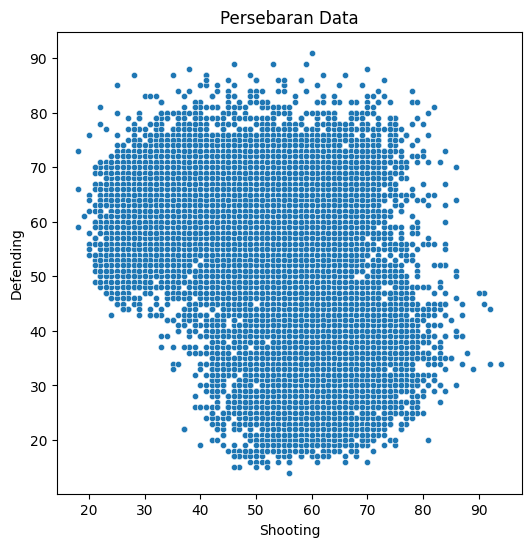

In [10]:
#202431163_Maftuh Faisal
plt.figure(figsize=(6,6))
sns.scatterplot(x='shooting', y='defending', data=df, s=20)
plt.title('Persebaran Data')
plt.xlabel('Shooting')
plt.ylabel('Defending')
plt.show()

In [11]:
#202431163_Maftuh Faisal
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['shooting', 'defending']])

pd.DataFrame(X_scaled, columns=['shooting', 'defending']).agg(['mean', 'std']).round(3)

,shooting,defending
mean,0.0,0.0
std,1.0,1.0


### Menentukan jumlah klaster dengan metode Elbow

In [12]:
#202431163_Maftuh Faisal
wcss = []
for i in range(1, 11):
    kmModel = KMeans(n_clusters=i, n_init=10, random_state=0)
    kmModel.fit(X_scaled)
    wcss.append(kmModel.inertia_)

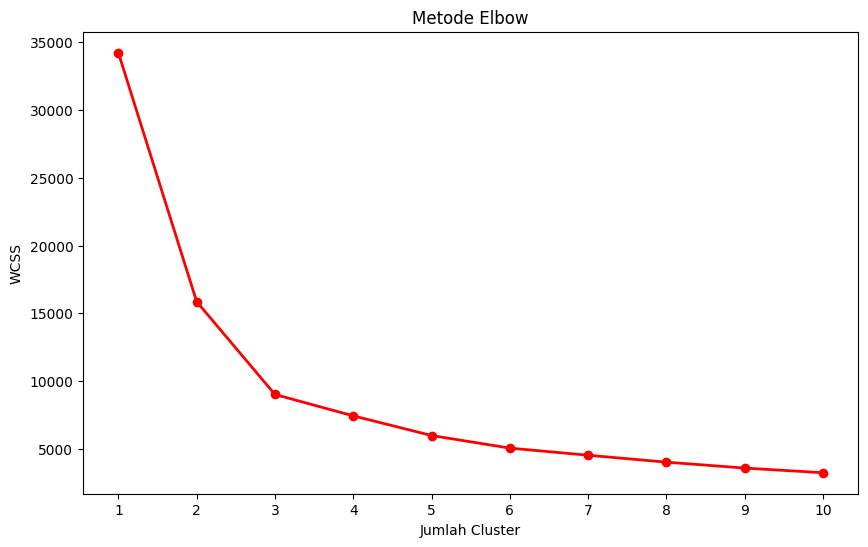

In [13]:
#202431163_Maftuh Faisal
plt.figure(figsize=(10,6))
plt.plot(range(1,11), wcss, linewidth=2, color='red', marker='o')
plt.xlabel('Jumlah Cluster')
plt.xticks(np.arange(1,11,1))
plt.ylabel('WCSS')
plt.title('Metode Elbow')
plt.show()

In [14]:
#202431163_Maftuh Faisal
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    lab = km.fit_predict(X_scaled)
    hasil.append({
        'k': k,
        'silhouette': round(silhouette_score(X_scaled, lab), 4),
        'DBI': round(davies_bouldin_score(X_scaled, lab), 4)
    })
pd.DataFrame(hasil)

,k,silhouette,DBI
0,2,0.4807,0.7921
1,3,0.4721,0.7517
2,4,0.4094,0.9178
3,5,0.3606,0.9918
4,6,0.3659,0.9027


In [15]:
#202431163_Maftuh Faisal
kmModelFix = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = kmModelFix.fit_predict(X_scaled)

print("Centroid (skala terstandardisasi):")
print(kmModelFix.cluster_centers_)

print("\nCentroid (skala asli):")
print(scaler.inverse_transform(kmModelFix.cluster_centers_))

print("\nJumlah anggota tiap klaster:")
print(pd.Series(labels).value_counts().sort_index())

Centroid (skala terstandardisasi):
[[ 0.41796954  0.68377895]
 [ 0.71788202 -1.1920294 ]
 [-1.20526712  0.60076682]]

Centroid (skala asli):
[[58.21827592 62.77351419]
 [62.43240988 32.40554072]
 [35.40983309 61.42960813]]

Jumlah anggota tiap klaster:
0    5597
1    5990
2    5520
Name: count, dtype: int64


In [16]:
#202431163_Maftuh Faisal
df['label'] = labels
df.head()

,shooting,defending,label
0,92.0,34.0,1
1,92.0,44.0,1
2,94.0,34.0,1
3,83.0,37.0,1
4,86.0,64.0,0


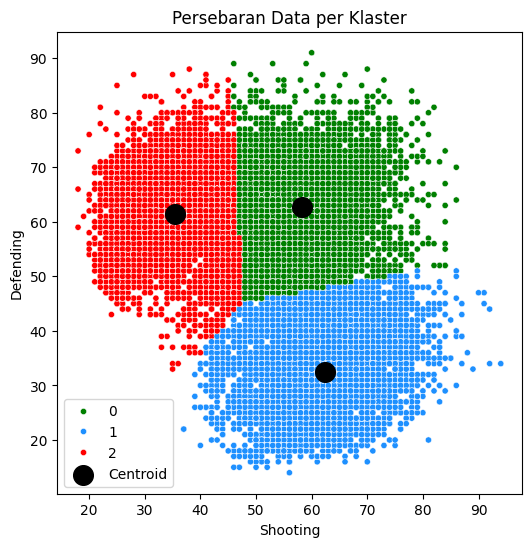

In [17]:
#202431163_Maftuh Faisal
plt.figure(figsize=(6,6))
sns.scatterplot(x='shooting', y='defending',
                hue='label', palette=['green', 'dodgerblue', 'red'],
                legend='full', data=df, s=20)
centroid_asli = scaler.inverse_transform(kmModelFix.cluster_centers_)
plt.scatter(centroid_asli[:,0], centroid_asli[:,1],
            s=200, c='black', zorder=5, label='Centroid')
plt.title('Persebaran Data per Klaster')
plt.xlabel('Shooting')
plt.ylabel('Defending')
plt.legend()
plt.show()

In [18]:
#202431163_Maftuh Faisal
posisi = data.loc[df.index, 'player_positions'].str.split(',').str[0]
pd.crosstab(df['label'], posisi)

player_positions,CAM,CB,CDM,CF,CM,LB,LM,LW,LWB,RB,RM,RW,RWB,ST
label,,,,,,,,,,,,,,
0,317,494,1090,17,1745,617,203,36,93,552,228,66,89,50
1,805,0,0,125,120,1,790,394,0,2,770,425,1,2557
2,29,2845,575,0,308,742,23,5,78,792,30,4,88,1


### Evaluasi dengan Davies-Bouldin Index (semakin kecil semakin baik)

In [19]:
#202431163_Maftuh Faisal
profil = df.groupby('label')[['shooting', 'defending']].mean().round(1)
print(profil)

nama = {0: 'Gelandang', 1: 'Penyerang', 2: 'Bek'}
df['nama_klaster'] = df['label'].map(nama)
print()
print(df.groupby('nama_klaster')[['shooting', 'defending']].mean().round(1))

       shooting  defending
label                     
0          58.2       62.8
1          62.4       32.4
2          35.4       61.4

              shooting  defending
nama_klaster                     
Bek               35.4       61.4
Gelandang         58.2       62.8
Penyerang         62.4       32.4


### Interpretasi klaster
Posisi pemain tidak dipakai saat klasterisasi. Di sini posisi utama dipakai hanya untuk membaca hasilnya.

In [20]:
#202431163_Maftuh Faisal
print("DBI akhir  :", round(davies_bouldin_score(X_scaled, labels), 4))
print("Silhouette :", round(silhouette_score(X_scaled, labels), 4))

DBI akhir  : 0.7517
Silhouette : 0.4721
